# EMQA_L4_gpd_tail

**Above the threshold the Pareto curve follows the data; the normal curve does not**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_gpd_tail/EMQA_L4_gpd_tail.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
START = pd.Timestamp('2015-01-01')
END = pd.Timestamp('2026-10-31')           # cut-off of Lecture 4: last complete month of the download
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO']].reindex(CAL)           # full calendar: missing days stay missing
X = P.diff()                           # daily change X_t = P_t - P_{t-1}; a change next to a gap is missing
print('daily prices', d(START), 'to', d(END), '| missing days in Romania:', int(P['RO'].isna().sum()))

daily prices 2015-01-01 to 2026-10-31 | missing days in Romania: 5


In [4]:
# the GARCH filter uses the arch package (not preinstalled on Google Colab)
import importlib.util, subprocess, sys
if importlib.util.find_spec('arch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model

## Filter, then fit the tail

$X_t=\mu_{d(t)}+\sigma_t z_t$: weekday mean $\mu_d$, GARCH(1,1) volatility $\sigma_t$, standardised residuals $z_t$. Above the threshold $u$ (90% quantile of $z$) the excesses follow a generalised Pareto distribution, $P(Z>z)=\frac{N_u}{n}\big(1+\xi\frac{z-u}{\beta}\big)^{-1/\xi}$.

In [5]:
T0, W_G, REFIT, U_EVT = pd.Timestamp('2017-01-01'), 730, 21, 0.90


def garch_filter(e):
    res = arch_model(e, mean='Zero', vol='GARCH', p=1, q=1, dist='normal', rescale=False).fit(disp='off')
    return np.asarray(res.conditional_volatility)


def gpd_tail(z, u_q=U_EVT):
    u = np.quantile(z, u_q)
    exc = z[z > u] - u
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    return u, xi, beta, len(exc), len(z)


def standardised(hist):
    # weekday-demeaned changes divided by their GARCH(1,1) volatility
    hw = hist[-W_G:]
    mdow = hw.groupby(hw.index.dayofweek).mean()
    e = (hw - mdow.reindex(hw.index.dayofweek).values).values
    return e / garch_filter(e)

In [6]:
# the refits of the rolling forecast: every 21 days from 2017-01-01, on the 730 changes before the refit day
refits = []
for t in pd.date_range(T0, END, freq='D')[::REFIT]:
    hist = X['RO'][:t - pd.Timedelta(days=1)].dropna()
    u, xi, beta, n_u, n = gpd_tail(standardised(hist))
    refits.append((d(t), xi, beta))
show('evt.refit_last', refits[-1][0])
show('evt.xi_last', round(refits[-1][1], 3))
show('evt.beta_last', round(refits[-1][2], 3))
show('evt.share_xi_pos', round(100 * np.mean([r[1] > 0 for r in refits]), 0))
print('number of refits:', len(refits))

evt.refit_last               = 2026-10-11
evt.xi_last                  = 0.182
evt.beta_last                = 0.569
evt.share_xi_pos             = 53.0
number of refits: 171


chart fit: u = 1.147, xi = 0.194, beta = 0.539, 73 exceedances of 730


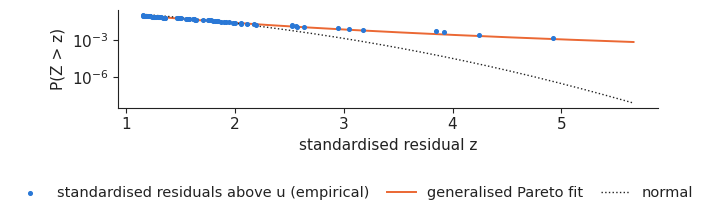

In [7]:
# the chart: the filter fitted on the 730 changes before the cut-off
z = np.sort(standardised(X['RO'][:END - pd.Timedelta(days=1)].dropna()))
u, xi, beta, n_u, n = gpd_tail(z)
print(f'chart fit: u = {u:.3f}, xi = {xi:.3f}, beta = {beta:.3f}, {n_u} exceedances of {n}')
fig, ax = plt.subplots(figsize=(6.4, 2.2))
zt = z[z > u]
sv = 1 - np.searchsorted(z, zt, side='left') / len(z)
ax.scatter(zt, sv, s=7, color=PAL['RO'], label='standardised residuals above u (empirical)', zorder=3)
gx = np.linspace(u, zt.max() * 1.15, 200)
ax.plot(gx, (n_u / n) * stats.genpareto.sf(gx - u, xi, scale=beta), color=PAL['DE_LU'], lw=1.4,
        label='generalised Pareto fit')
ax.plot(gx, stats.norm.sf(gx), color='#222222', ls=':', lw=1.0, label='normal')
ax.set_yscale('log')
ax.set_xlabel('standardised residual z')
ax.set_ylabel('P(Z > z)')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('gpd_tail.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()